#ДЗ.6 Затухание
Добавить экспоненциальное затухание света с длиной затухания 8 метров.
Получить энергетический отклик детектора для источников с энергией 1 МэВ, расположенных в разных точках вдоль вертикальной оси детектора.
Сравнить полученные распределения с результатами симуляции тех же источников без затухания.

In [39]:
import numpy as np

class Detector:#новый параметр добавили L (длина затухания)
    def __init__(self, R: float, N: int, r: float, a: float, L: float):
     self.R = R
     self.N = N
     self.r = r
     self.a = a
     self.L = L

    def dots_on_parallels(self):

       
        n_theta = 5
        n_phi = 8

        cos_theta = 1 - 2*(np.arange(n_theta) + 0.5)/n_theta
        theta = np.arccos(cos_theta)
        phi = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

        dots = []

        for i in range(n_theta):
            for j in range(n_phi):
                x = self.R * np.sin(theta[i]) * np.cos(phi[j])
                y = self.R * np.sin(theta[i]) * np.sin(phi[j])
                z = self.R * np.cos(theta[i])

                dots.append([x, y, z])

        self.photocathode_centers = np.array(dots)

    def is_on_photocathode(self, coordinats):
        

        lengths = np.linalg.norm(self.photocathode_centers - coordinats, axis=1)

        return np.any(lengths <= self.r)

    
    def intersection(self, coordinats, direction):
        projection = np.dot(coordinats, direction)

        distance = -projection + np.sqrt(projection**2 + self.R**2 - np.dot(coordinats, coordinats)) 
        

        point = coordinats + distance * direction

        return self.is_on_photocathode(point)

    def photoelectrons(self):

        return np.random.poisson(self.a)

 
    # Новые три метода

    def photon_distance(self, coordinats, direction):
        # Находим расстояние от источника до поверхности детектора вдоль направления движения фотона

        projection = np.dot(coordinats, direction)

        distance = -projection + np.sqrt(
            projection**2 + self.R**2 - np.dot(coordinats, coordinats)
        )

        return distance

    def is_absorbed(self, distance):
        # Вероятность поглощения фотона на пути длиной distance

        probability = 1 - np.exp(-distance / self.L)

        # Если случайное число от 0 до 1 меньше probability, считаем что фотон поглотился
        return np.random.random() < probability

  
    def photon_reaches_photocathode(self, coordinats, direction):
        # Проверяем, достиг ли фотон фотокатода с учетом затухания

        if not self.intersection(coordinats, direction):
            return False

        distance = self.photon_distance(coordinats, direction)

        return not self.is_absorbed(distance)




detector = Detector(R=2.0, N=40, r=0.1, a=0.5, L=8.0)
detector.dots_on_parallels()

In [40]:
class Source:
    def __init__(self, Y: int):
        self.Y = Y

    def photon_directions(self, E: float):
        N = np.random.poisson(self.Y * E)

        for i in range(0, N, 100): 
            n = min(100, N - i)

            phi = np.random.uniform(0, 2*np.pi, n)
            cosTheta = np.random.uniform(-1, 1, n)
            sinTheta = np.sqrt(1 - cosTheta**2)

            x = sinTheta * np.cos(phi)
            y = sinTheta * np.sin(phi)
            z = cosTheta

            yield np.array([x, y, z]).T


source = Source(Y=10000)

In [41]:

# Моделируем событие с энергией 1 МэВ в центре детектора с учетом затухания света

coordinats = np.array([0, 0, 0])

Q = 0
n = 0

for directions in source.photon_directions(E=1.0):
    for direction in directions:
        if detector.photon_reaches_photocathode(coordinats, direction):
            n += 1
            Q += detector.photoelectrons()

print("Число фотонов, достигших фотокатодов:", n)
print("Полный собранный заряд:", Q)


Число фотонов, достигших фотокатодов: 178
Полный собранный заряд: 73


In [42]:
# Находим вероятности попадания фотонов с затуханием и без затухания

def photon_probabilities(coordinats):
    A = 0  # общее число фотонов
    B = 0  # число фотонов, попавших на фотокатоды
    C = 0  # сумма вероятностей что попавшие фотоны не поглотятся по пути

    for directions in source.photon_directions(E=10.0):
        projection = np.dot(directions, coordinats)

        distance = -projection + np.sqrt(
            projection**2 + detector.R**2 - np.dot(coordinats, coordinats)
        )

        points = coordinats + distance[:, None] * directions

        # Проверяем попадание на фотокатоды
        products = np.dot(points, detector.photocathode_centers.T)

        hits = np.any(
            products >= detector.R**2 - detector.r**2 / 2,
            axis=1
        )

        A += len(directions)
        B += np.sum(hits)

        # Учитем вероятность того что попавшие фотоны не поглотились 
        C += np.sum(hits * np.exp(-distance / detector.L))

    p_without = B / A
    p_with = C / A

    return p_without, p_with


In [43]:
# Вычисляем вероятности попадания для пяти разных положений источника на оси z

z_positions = [-1, -0.5, 0, 0.5, 1]

probabilities_without = []
probabilities_with = []

for z in z_positions:
    coordinats = np.array([0, 0, z])

    p_without, p_with = photon_probabilities(coordinats)

    probabilities_without.append(p_without)
    probabilities_with.append(p_with)

    print("z =", z, "м")
    print("вероятность без затухания:", round(p_without, 5))
    print("вероястность с затуханием:", round(p_with, 5))
    print()


z = -1 м
вероятность без затухания: 0.02404
вероястность с затуханием: 0.01906

z = -0.5 м
вероятность без затухания: 0.02426
вероястность с затуханием: 0.01899

z = 0 м
вероятность без затухания: 0.02416
вероястность с затуханием: 0.01882

z = 0.5 м
вероятность без затухания: 0.02432
вероястность с затуханием: 0.01904

z = 1 м
вероятность без затухания: 0.0237
вероястность с затуханием: 0.01876



In [44]:
# Генерируем полный заряд для 1000 событий

def gen_charges(E, p):
    n = np.random.poisson(source.Y * E * p, size=1000)  # Разыгрываем число фотонов, достигших фотокатодов
    Q = np.random.poisson(detector.a * n)               # Разыгрываем полный заряд каждого события

    return Q


In [45]:
# Моделируем 1000 событий при энергии 1 МэВ для разных положений источника с затуханием и без него

charges_without = []
charges_with = []

for p_without, p_with in zip(probabilities_without, probabilities_with):
    charges_without.append(gen_charges(1.0, p_without))
    charges_with.append(gen_charges(1.0, p_with))


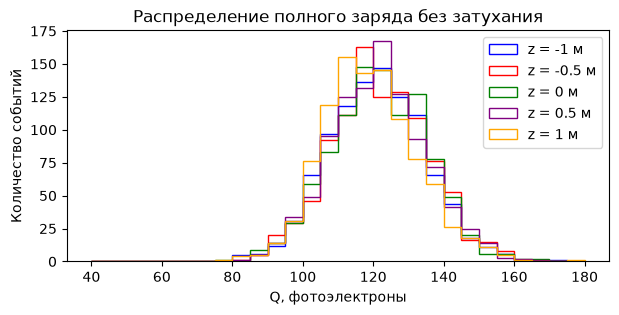

In [46]:
# Распределения полного заряда без затухания
import numpy as np
import matplotlib.pyplot as plt
colors = ['blue', 'red', 'green', 'purple', 'orange']
bins = np.arange(40, 181, 5)

plt.figure(figsize=(7, 3))

for z, Q, color in zip(z_positions, charges_without, colors):
    plt.hist(Q, bins=bins, histtype='step', color=color, label=f'z = {z} м')

plt.xlabel('Q, фотоэлектроны')
plt.ylabel('Количество событий')
plt.title('Распределение полного заряда без затухания')
plt.legend()
plt.show()


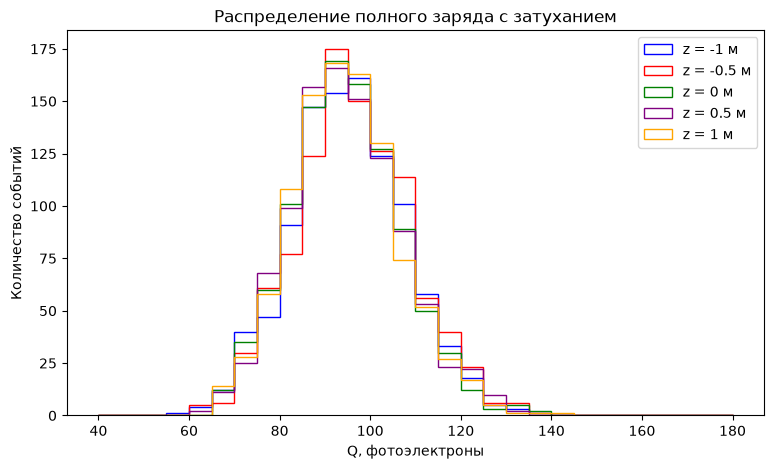

In [47]:

# Распределения полного заряда с затуханием

plt.figure(figsize=(9, 5))

for z, Q, color in zip(z_positions, charges_with, colors):
    plt.hist(Q, bins=bins, histtype='step', color=color, label=f'z = {z} м')

plt.xlabel('Q, фотоэлектроны')
plt.ylabel('Количество событий')
plt.title('Распределение полного заряда с затуханием')
plt.legend()
plt.show()


# Сравним средние заряды с затуханием и без него для разных положений источника вдоль оси z

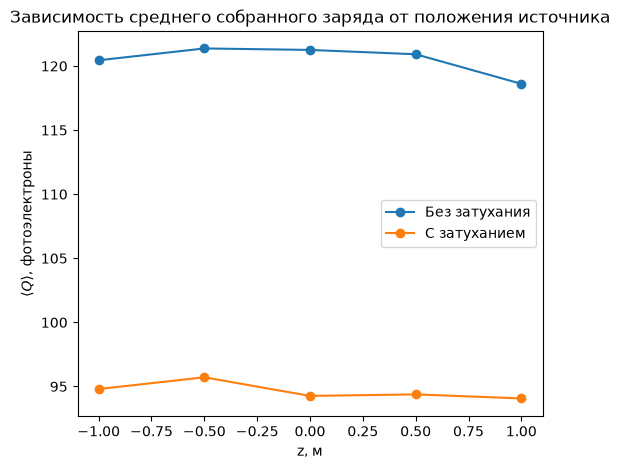

In [48]:
mean_without = []
mean_with = []

for Q_without, Q_with in zip(charges_without, charges_with):
    mean_without.append(np.mean(Q_without))
    mean_with.append(np.mean(Q_with))

plt.figure(figsize=(6, 5))

plt.plot(z_positions, mean_without, 'o-', label='Без затухания')
plt.plot(z_positions, mean_with, 'o-', label='С затуханием')

plt.xlabel('z, м')
plt.ylabel(r'$\langle Q \rangle$, фотоэлектроны')
plt.title('Зависимость среднего собранного заряда от положения источника')
plt.legend()
plt.show()


In [ ]:
for z, Q_without, Q_with in zip(z_positions, mean_without, mean_with):  #для вычисления относительного уменьшение среднего заряда

    change = (Q_without - Q_with) / Q_without * 100

    print("z =", z, "м, уменьшение заряда на", round(change, 2), "%")


z = -1 м, уменьшение заряда на 21.3 %
z = -0.5 м, уменьшение заряда на 21.14 %
z = 0 м, уменьшение заряда на 22.26 %
z = 0.5 м, уменьшение заряда на 21.95 %
z = 1 м, уменьшение заряда на 20.69 %


то есть из графиков и данных выше видно, что при добавлении экспоненциального затухания средний собранный заряд уменьшился для всех пяти рассмотренных положений источника (jтносительное "уменьшение" примерно 20%).Таким образом, затухание света приводит к уменьшению энергетического отклика детектора и величина этого эффекта зависит от положения источника.